<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 2 · Sesión 2: Estimadores, intervalos, teoremas límite y verosimilitud</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: sesgo y varianza, IC de una PD, LGN, TLC, bootstrap, MLE y lectura de salidas estadísticas</div>
</div>

## Objetivos de la sesión (2 horas)

1. Distinguir **población, muestra, parámetro y estimador**, y medir **sesgo, varianza y error cuadrático medio**.
2. Construir **intervalos de confianza** para una PD (Wald, Wilson, Clopper-Pearson, Jeffreys) y ver cuándo falla cada uno.
3. Comprobar con simulación la **ley de los grandes números** y el **teorema central del límite**.
4. Entender la **verosimilitud** y el **estimador de máxima verosimilitud** (MLE): la base de la regresión logística.
5. Leer la **salida estadística** de un modelo (coeficientes, errores estándar, z, p-valores, IC, log-verosimilitud, pseudo R²).

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Población, muestra y estimadores |
| 2 | 25 min | Intervalos de confianza para una PD |
| 3 | 25 min | LGN, TLC y bootstrap |
| 4 | 30 min | Verosimilitud y MLE |
| 5 | 15 min | Lectura de resultados estadísticos |
| 6 | 5 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from scipy import stats, optimize
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
german = pd.read_csv(DATA / "german_credit.csv")
rng = np.random.default_rng(2027)

## 1. Población, muestra y estimadores
Tratemos las 60 mil solicitudes como la **población** (PD verdadera $p$) y extraigamos **muestras** como las que tendría un analista con poca historia.

- **Estimador** de la PD: $\hat p = \frac{1}{n}\sum D_i$ (la tasa de incumplimiento observada).
- **Sesgo:** $E[\hat p] - p$. **Varianza:** $\text{Var}(\hat p) = p(1-p)/n$. **ECM** = sesgo² + varianza.

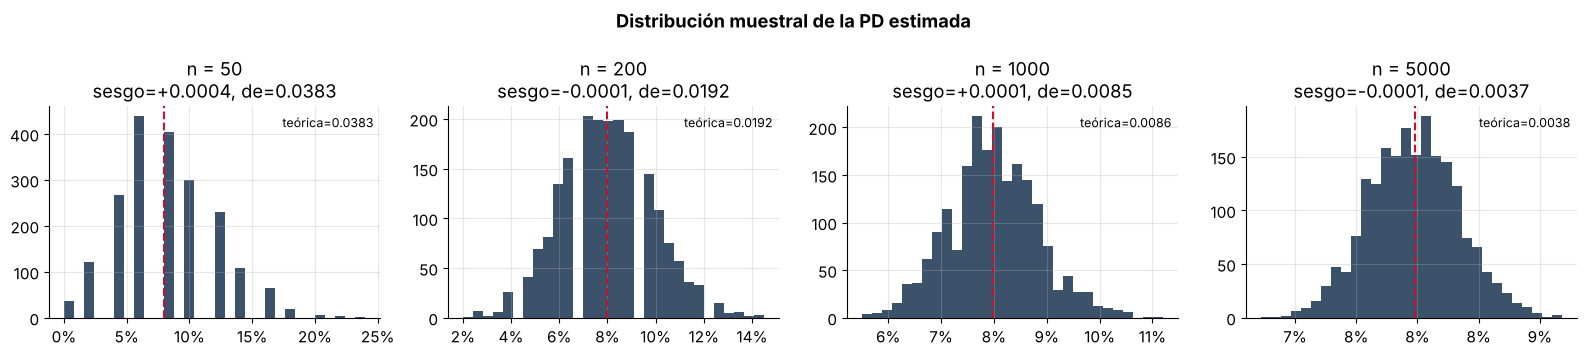

In [2]:
p_pob = app.TARGET.mean()
tamanos = [50, 200, 1000, 5000]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
for a, n in zip(ax, tamanos):
    est = np.array([app.TARGET.sample(n, random_state=int(s)).mean() for s in rng.integers(0, 1e9, 2000)])
    a.hist(est, bins=30, color=AZUL, alpha=.8); a.axvline(p_pob, color=ROJO, ls="--")
    a.set_title(f"n = {n}\nsesgo={est.mean() - p_pob:+.4f}, de={est.std():.4f}"); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    a.text(0.98, 0.9, f"teórica={np.sqrt(p_pob * (1 - p_pob) / n):.4f}", transform=a.transAxes, ha="right", fontsize=9)
fig.suptitle("Distribución muestral de la PD estimada", weight="bold"); plt.tight_layout(); plt.show()

**Un estimador sesgado pero útil:** en segmentos con pocos datos se suele "encoger" la PD hacia la media de la cartera (*shrinkage*):
$$\hat p_{shrink} = \frac{n}{n + k}\hat p + \frac{k}{n + k}\, \bar p$$
Tiene **sesgo**, pero mucha menos **varianza**. Es la misma idea que reaparece en la regularización (Módulo 3), en las *target statistics* de CatBoost (Módulo 5) y en Bayes (Módulo 10).

In [3]:
# Segmento chico con PD verdadera 15 %: ¿quién estima mejor, la tasa cruda o la "encogida"?
p_seg, n, k, sims = 0.15, 40, 30, 20000
crudo = rng.binomial(n, p_seg, sims) / n
shrink = n / (n + k) * crudo + k / (n + k) * p_pob
for nombre, e in [("Tasa cruda", crudo), ("Shrinkage", shrink)]:
    print(f"{nombre:11s} sesgo={e.mean() - p_seg:+.4f}  varianza={e.var():.5f}  ECM={((e - p_seg) ** 2).mean():.5f}")

Tasa cruda  sesgo=+0.0002  varianza=0.00316  ECM=0.00316
Shrinkage   sesgo=-0.0300  varianza=0.00103  ECM=0.00193


## 2. Intervalos de confianza para una PD
| Método | Idea | Problema |
|---|---|---|
| **Wald** | $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ | Falla con $n$ chico o $p$ cercano a 0 (¡puede dar límites negativos!) |
| **Wilson** | Invierte el test *score* | Buen comportamiento general |
| **Clopper-Pearson** | Exacto, basado en la Binomial | Conservador |
| **Jeffreys** | Bayesiano con prior Beta(½, ½) | Muy usado en validación de PD (BCE / EBA) |

In [4]:
casos = [(2, 150), (10, 150), (40, 500), (800, 10000)]
filas = []
for x, n in casos:
    for m in ["normal", "wilson", "beta", "jeffreys"]:
        lo, hi = proportion_confint(x, n, alpha=0.05, method=m)
        filas.append({"defaults/n": f"{x}/{n}", "p_hat": x / n, "método": {"normal": "Wald", "beta": "Clopper-Pearson"}.get(m, m.title()),
                      "límite inf": lo, "límite sup": hi, "ancho": hi - lo})
pd.DataFrame(filas).style.format({"p_hat": "{:.2%}", "límite inf": "{:.2%}", "límite sup": "{:.2%}", "ancho": "{:.2%}"})

,defaults/n,p_hat,método,límite inf,límite sup,ancho
0,2/150,1.33%,Wald,0.00%,3.17%,3.17%
1,2/150,1.33%,Wilson,0.37%,4.73%,4.36%
2,2/150,1.33%,Clopper-Pearson,0.16%,4.73%,4.57%
3,2/150,1.33%,Jeffreys,0.28%,4.21%,3.93%
4,10/150,6.67%,Wald,2.67%,10.66%,7.98%
5,10/150,6.67%,Wilson,3.66%,11.84%,8.18%
6,10/150,6.67%,Clopper-Pearson,3.24%,11.92%,8.68%
7,10/150,6.67%,Jeffreys,3.48%,11.50%,8.02%
8,40/500,8.00%,Wald,5.62%,10.38%,4.76%
9,40/500,8.00%,Wilson,5.93%,10.71%,4.78%


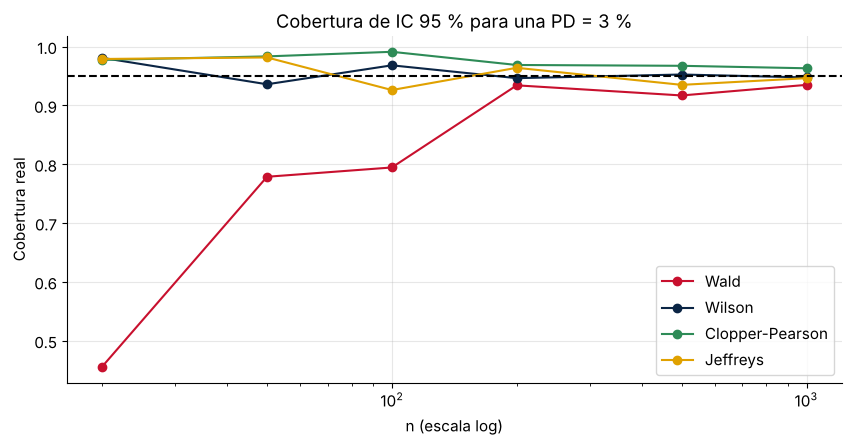

In [5]:
# Cobertura real de cada método: ¿el IC 95 % contiene a la PD verdadera el 95 % de las veces?
def cobertura(p, n, metodo, sims=5000):
    x = rng.binomial(n, p, sims)
    lo, hi = proportion_confint(x, n, alpha=0.05, method=metodo)
    return ((lo <= p) & (p <= hi)).mean()
ns = [20, 50, 100, 200, 500, 1000]
fig, ax = plt.subplots()
for m, c, lab in [("normal", ROJO, "Wald"), ("wilson", AZUL, "Wilson"), ("beta", VERDE, "Clopper-Pearson"), ("jeffreys", ORO, "Jeffreys")]:
    ax.plot(ns, [cobertura(0.03, n, m) for n in ns], marker="o", color=c, label=lab)
ax.axhline(0.95, color="black", ls="--"); ax.set_xscale("log"); ax.set_xlabel("n (escala log)"); ax.set_ylabel("Cobertura real")
ax.set_title("Cobertura de IC 95 % para una PD = 3 %"); ax.legend(); plt.show()

**Conclusión práctica:** para carteras de **bajo incumplimiento** o segmentos chicos **no uses Wald**. Wilson o Jeffreys son mejores opciones por defecto.

## 3. Ley de los grandes números, TLC y bootstrap
- **LGN:** $\hat p_n \to p$ cuando $n \to \infty$. La tasa observada converge a la PD.
- **TLC:** $\frac{\hat p_n - p}{\sqrt{p(1-p)/n}} \xrightarrow{d} N(0,1)$. Es lo que justifica los intervalos y tests basados en la normal.

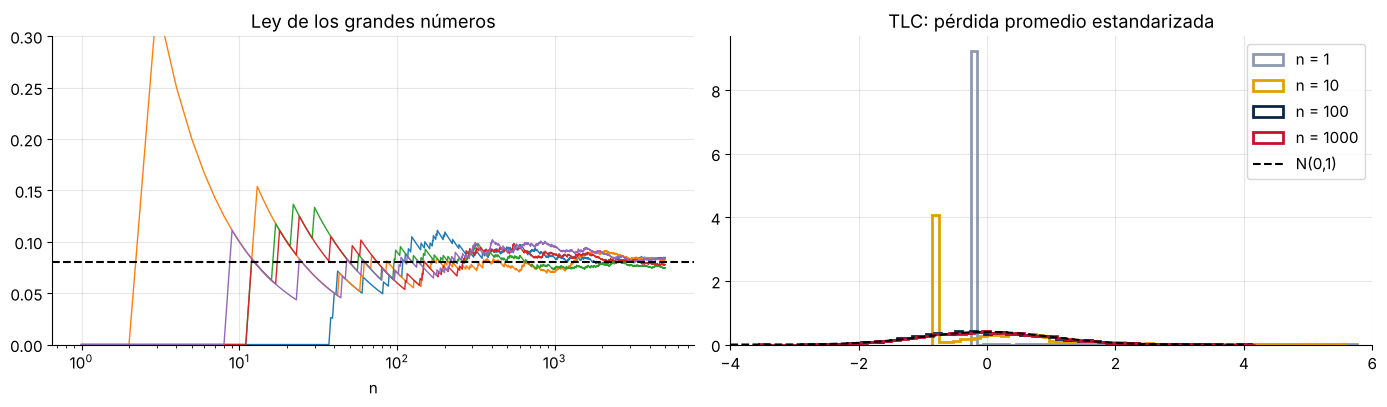

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for _ in range(5):
    d = rng.binomial(1, p_pob, 5000)
    ax[0].plot(np.arange(1, 5001), d.cumsum() / np.arange(1, 5001), lw=1)
ax[0].axhline(p_pob, color="black", ls="--"); ax[0].set_xscale("log"); ax[0].set_title("Ley de los grandes números"); ax[0].set_xlabel("n")
ax[0].set_ylim(0, .3)

# TLC: la suma de pérdidas de 'n' créditos con distribución muy asimétrica
perd_ind = lambda size: rng.binomial(1, p_pob, size) * rng.beta(2, 1.5, size)    # pérdida = default x LGD aleatoria
for n, c in [(1, GRIS), (10, ORO), (100, AZUL), (1000, ROJO)]:
    medias = perd_ind((5000, n)).mean(axis=1)
    z = (medias - medias.mean()) / medias.std()
    ax[1].hist(z, bins=60, density=True, histtype="step", lw=2, color=c, label=f"n = {n}")
xx = np.linspace(-4, 4, 200); ax[1].plot(xx, stats.norm.pdf(xx), "k--", label="N(0,1)")
ax[1].set_xlim(-4, 6); ax[1].legend(); ax[1].set_title("TLC: pérdida promedio estandarizada")
plt.tight_layout(); plt.show()

### Bootstrap: incertidumbre sin fórmula
Cuando no hay fórmula sencilla para el error estándar (p. ej., el **AUC** o el **Gini** de un modelo), remuestreamos con reemplazo.

AUC = 0.7310  IC95% bootstrap = [0.7240, 0.7378]  ->  Gini = 0.462


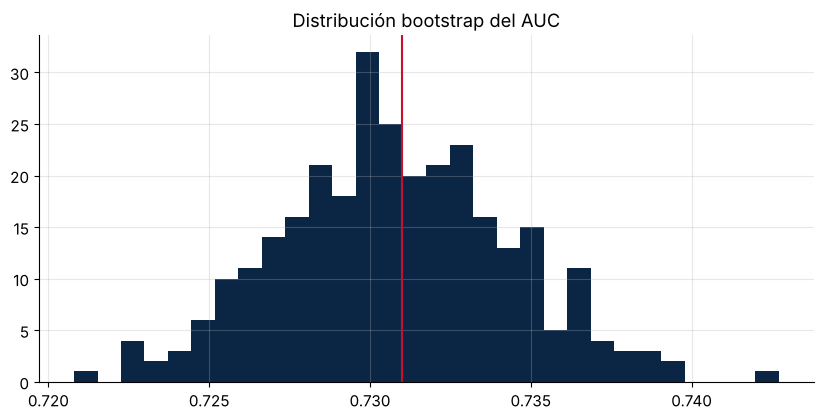

In [7]:
from sklearn.metrics import roc_auc_score
score = app[["EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1).fillna(0.5)
y = app.TARGET.values
auc_obs = roc_auc_score(y, -score)
boot = []
idx = np.arange(len(y))
for _ in range(300):
    b = rng.choice(idx, len(idx), replace=True)
    boot.append(roc_auc_score(y[b], -score.values[b]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"AUC = {auc_obs:.4f}  IC95% bootstrap = [{lo:.4f}, {hi:.4f}]  ->  Gini = {2 * auc_obs - 1:.3f}")
plt.hist(boot, bins=30, color=AZUL); plt.axvline(auc_obs, color=ROJO); plt.title("Distribución bootstrap del AUC"); plt.show()

## 4. Verosimilitud y máxima verosimilitud
Dados datos $d_1, \dots, d_n$ con $D_i \sim \text{Bernoulli}(p)$:
$$\mathcal{L}(p) = \prod_{i=1}^n p^{d_i}(1-p)^{1-d_i}, \qquad \ell(p) = \log \mathcal{L}(p) = k \log p + (n-k)\log(1-p)$$
Derivando e igualando a cero: $\hat p_{MLE} = k/n$. La **curvatura** de $\ell$ en el máximo (información de Fisher) da el error estándar:
$$I(p) = \frac{n}{p(1-p)} \quad\Rightarrow\quad SE(\hat p) = \sqrt{\hat p(1-\hat p)/n}$$

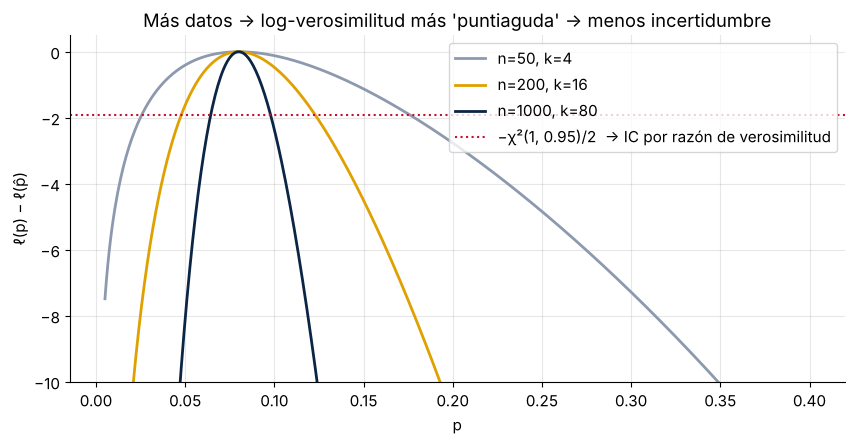

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
grid = np.linspace(0.005, 0.4, 500)
for n, c in [(50, GRIS), (200, ORO), (1000, AZUL)]:
    k = round(0.08 * n)
    ll = k * np.log(grid) + (n - k) * np.log(1 - grid)
    ax.plot(grid, ll - ll.max(), color=c, lw=2, label=f"n={n}, k={k}")
ax.axhline(-1.92, color=ROJO, ls=":", label="−χ²(1, 0.95)/2  → IC por razón de verosimilitud")
ax.set_ylim(-10, 0.5); ax.set_xlabel("p"); ax.set_ylabel("ℓ(p) − ℓ(p̂)"); ax.legend(); ax.set_title("Más datos → log-verosimilitud más 'puntiaguda' → menos incertidumbre")
plt.show()

### MLE numérico: de una PD constante a una PD que depende de $x$
Si dejamos que $p_i$ dependa de las características del cliente mediante $p_i = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_i)}}$, maximizar $\ell(\beta)$ es exactamente **estimar una regresión logística**. Hagámoslo "a mano" con un optimizador y comparemos con `statsmodels`.

In [9]:
x = german["duration_in_month"].values
yv = german["default"].values
def neg_loglik(beta):
    eta = beta[0] + beta[1] * x
    return -np.sum(yv * eta - np.log1p(np.exp(eta)))
opt = optimize.minimize(neg_loglik, x0=[0, 0], method="BFGS")
# Error estándar desde el Hessiano analítico de la log-verosimilitud: H = X' W X, con W = diag(p(1-p))
Xd = np.column_stack([np.ones_like(x), x]).astype(float)
p_fit = 1 / (1 + np.exp(-Xd @ opt.x))
H = Xd.T @ (Xd * (p_fit * (1 - p_fit))[:, None])
se_manual = np.sqrt(np.diag(np.linalg.inv(H)))       # (la aproximación hess_inv de BFGS NO es confiable para esto)
print("MLE manual:   beta =", opt.x.round(4), " SE aprox =", se_manual.round(4), " logLik =", round(-opt.fun, 2))
m = sm.Logit(yv, sm.add_constant(x)).fit(disp=0)
print("statsmodels:  beta =", m.params.round(4), " SE =", m.bse.round(4), " logLik =", round(m.llf, 2))

MLE manual:   beta = [-1.6664  0.0375]  SE aprox = [0.1466 0.0057]  logLik = -588.56
statsmodels:  beta = [-1.6664  0.0375]  SE = [0.1466 0.0057]  logLik = -588.56


## 5. Lectura de resultados estadísticos
Estimemos un modelo con varias variables del *German Credit* (datos reales, 1 000 créditos, 30 % malos) y leamos la salida **como lo haría un comité de validación**.

In [10]:
g = german.copy()
g["sin_cuenta_corriente"] = (g["status_of_existing_checking_account"] == "no checking account").astype(int)
g["historia_critica"] = (g["credit_history"].str.contains("critical")).astype(int)
g["ahorro_bajo"] = (g["savings_account_and_bonds"] == "... < 100 DM").astype(int)
g["log_monto"] = np.log(g["credit_amount"])
X = sm.add_constant(g[["duration_in_month", "log_monto", "age_in_years", "sin_cuenta_corriente", "historia_critica", "ahorro_bajo",
                       "installment_rate_in_percentage_of_disposable_income"]])
modelo = sm.Logit(g["default"], X).fit(disp=0)
print(modelo.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                 1000
Model:                          Logit   Df Residuals:                      992
Method:                           MLE   Df Model:                            7
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.1621
Time:                        21:05:02   Log-Likelihood:                -511.82
converged:                       True   LL-Null:                       -610.86
Covariance Type:            nonrobust   LLR p-value:                 2.926e-39
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
const                                                  -2.4208      1.139     -2.125      0.034      -4.654      -0.188
duration

In [11]:
res = pd.DataFrame({"coef": modelo.params, "odds_ratio": np.exp(modelo.params), "p_value": modelo.pvalues,
                    "OR_inf": np.exp(modelo.conf_int()[0]), "OR_sup": np.exp(modelo.conf_int()[1])})
res.style.format({"coef": "{:+.3f}", "odds_ratio": "{:.3f}", "p_value": "{:.4f}", "OR_inf": "{:.3f}", "OR_sup": "{:.3f}"}).map(
    lambda v: "color: #C8102E; font-weight: bold" if isinstance(v, float) and v < 0.05 else "", subset=["p_value"])

,coef,odds_ratio,p_value,OR_inf,OR_sup
const,-2.421,0.089,0.0336,0.010,0.829
duration_in_month,+0.034,1.034,0.0001,1.017,1.052
log_monto,+0.111,1.117,0.4420,0.843,1.480
age_in_years,-0.013,0.987,0.0672,0.974,1.001
sin_cuenta_corriente,-1.532,0.216,0.0000,0.150,0.311
historia_critica,-0.765,0.466,0.0001,0.320,0.676
ahorro_bajo,+0.659,1.933,0.0001,1.396,2.676
installment_rate_in_percentage_of_disposable_income,+0.219,1.245,0.0055,1.067,1.454


**Guía de lectura (para usar en clase):**

| Elemento | Cómo leerlo |
|---|---|
| `coef` | Cambio en **log-odds** de incumplir por una unidad de $x$ |
| `odds_ratio = e^coef` | Multiplicador de los *odds*: 1.5 significa +50 % en los odds de incumplir |
| `std err` | Incertidumbre del coeficiente (viene de la curvatura de la log-verosimilitud) |
| `z`, `P>|z|` | Test de Wald, H0: β = 0. Un p-valor bajo indica evidencia contra "no tiene efecto" |
| `[0.025, 0.975]` | IC 95 % del coeficiente. Si contiene 0, no es significativo al 5 % |
| `Log-Likelihood`, `LL-Null`, `LLR p-value` | Mejora del modelo frente a uno con solo constante (test de razón de verosimilitud) |
| `Pseudo R-squ.` (McFadden) | $1 - \ell_{modelo}/\ell_{nulo}$. Valores entre 0.1 y 0.3 son habituales en riesgo: **no se compara con el R² de MCO** |

> 🔎 **Caso para discutir:** en el *German Credit*, "sin cuenta corriente" e "historia crítica" **reducen** el riesgo estimado. ¿Error? Es un efecto conocido del dataset: la muestra viene de créditos **aprobados**, de modo que los clientes con historia "crítica" que pasaron la admisión fueron muy filtrados (**sesgo de selección / reject inference**). Un signo contraintuitivo debe investigarse antes de aceptarse.

> ⚠️ **Significancia estadística ≠ relevancia de negocio ≠ causalidad.** Con 1 millón de registros casi todo es "significativo". Con 1 000, una variable relevante puede no serlo. Además: ¿el signo tiene sentido económico? ¿Es estable en el tiempo?

## 6. Ejercicios
1. Calcula IC de Wilson y Jeffreys para la PD de cada `REGION_RATING_CLIENT`. ¿Se solapan?
2. ¿Cuál es el tamaño mínimo de muestra para estimar una PD de 2 % con un margen de ±0.5 pp al 95 %?
3. Agrega `age_in_years²` al modelo. ¿Mejora el log-likelihood? Haz el test de razón de verosimilitud a mano: $LR = 2(\ell_1 - \ell_0) \sim \chi^2_1$.
4. **Reto:** deriva $\hat p_{MLE} = k/n$ y la información de Fisher de la Bernoulli.